# Consulta de Temperaturas Interactivo por Ciudad y Mes

## Objetivo

El proyecto propuesto consistirá en la creación de un programa interactivo para la visualización de datos meteorológicos. Este programa permitirá a los usuarios visualizar los registros climáticos eligiendo el lugar y el més. El objetivo es aplicar los conceptos de creación de gráficos, personalización de estilos y combinarlo con las habilidades de desarrollo de programas con Python.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CARGAR DTAFRAME

In [2]:
df1= pd.read_csv("Datos+Meteorológicos_Arg_2023.csv")
df1

,Fecha,Ciudad,Temperatura Maxima,Temperatura Minima,Precipitacion,Velocidad del Viento,Humedad Relativa
0,1/1/2023,Buenos Aires,27,18,0.0,22.7,68.8
1,1/1/2023,Cordoba,35,18,0.0,33.8,61.7
2,1/1/2023,Rosario,23,21,0.0,10.6,80.0
3,1/1/2023,Mendoza,35,21,0.0,23.8,76.8
4,1/1/2023,Tucuman,36,18,17.2,25.7,54.9
...,...,...,...,...,...,...,...
1820,31/12/2023,Buenos Aires,15,12,0.0,17.9,49.2
1821,31/12/2023,Cordoba,15,7,0.0,17.8,62.4
1822,31/12/2023,Rosario,14,8,0.0,38.2,31.2
1823,31/12/2023,Mendoza,13,9,84.8,27.6,35.3


ASEGURAR LA VARIABLE DE TIEMPO

In [3]:
df1["Fecha"]=pd.to_datetime(df1["Fecha"],format="%d/%m/%Y")

In [4]:
Meses=[]
for i in df1["Fecha"]:
    Meses.append(i.month)

df1["Meses"]=Meses

In [5]:
print(df1["Fecha"].dtype)

datetime64[us]


In [6]:
print(df1["Meses"].dtype)

int64


In [7]:
print (df1)

          Fecha        Ciudad  Temperatura Maxima  Temperatura Minima  \
0    2023-01-01  Buenos Aires                  27                  18   
1    2023-01-01       Cordoba                  35                  18   
2    2023-01-01       Rosario                  23                  21   
3    2023-01-01       Mendoza                  35                  21   
4    2023-01-01       Tucuman                  36                  18   
...         ...           ...                 ...                 ...   
1820 2023-12-31  Buenos Aires                  15                  12   
1821 2023-12-31       Cordoba                  15                   7   
1822 2023-12-31       Rosario                  14                   8   
1823 2023-12-31       Mendoza                  13                   9   
1824 2023-12-31       Tucuman                  15                  10   

      Precipitacion  Velocidad del Viento  Humedad Relativa  Meses  
0               0.0                  22.7             

1


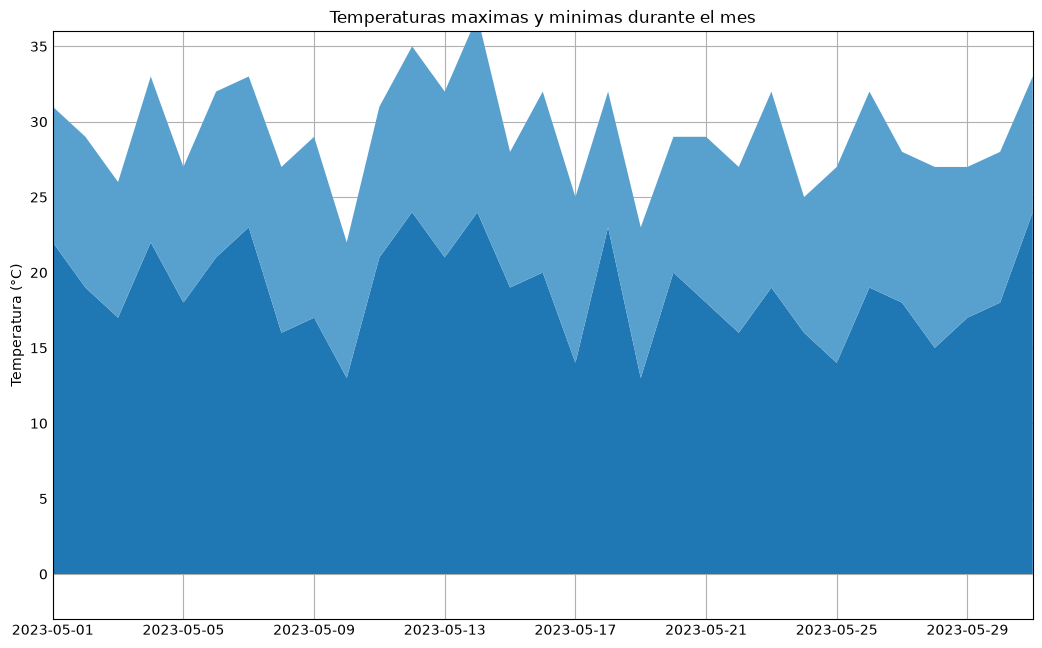

In [27]:
contador= 1

while contador==1:
    print(contador)
    Ciudad =input("Ingrese una Ciudad").capitalize()
    contador1=1
    while contador1==1:
        if Ciudad not in df1["Ciudad"].values:
            print("La ciudad no es valida")
            Ciudad =input("Ingrese una Ciudad").capitalize()
        else:
            contador1=contador1+1

    Mes=int(input("Ingrese un mes del año (Numero)"))

    contador2=1
    while contador2==1:
        if Mes not in df1["Meses"].values:
            print("El mes no es valido")
            while True:
                    try:
                     Mes=int(input("Ingrese un mes del año (Numero)"))
                     break  # Si logra convertirlo a entero, sale de este bucle y sigue con tu código
                    except ValueError:
                        print("Es inválido. Por favor, ingrese solo números.")
        else:
            contador2=contador2+1

    df2=df1[(df1["Ciudad"]== Ciudad) & (df1["Meses"]==Mes)]

    
    plt.style.use('_mpl-gallery')

    # make data
    x = df2["Fecha"]
    ay = df2["Temperatura Maxima"]
    by = df2["Temperatura Minima"]
    y = np.vstack([ay, by])

    # plot
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.stackplot(x, y)

    fecha_min = df2["Fecha"].min()
    fecha_max = df2["Fecha"].max()
    Tem_max=df1["Temperatura Maxima"].max()
    Tem_min=df1["Temperatura Minima"].min()


    ax.set(xlim=(fecha_min,fecha_max),
         
            ylim=(Tem_min,Tem_max), 

             title="Temperaturas maximas y minimas durante el mes",
               ylabel="Temperatura (°C)" )
   

    plt.show()

    Respuesta= input("Quiere continuar con su consulta ( Si o No)").capitalize()

    if Respuesta =="No":
        contador=contador+1
    


In [1]:
help(str.upper)

Help on method descriptor upper:

upper(self, /) unbound builtins.str method
    Return a copy of the string converted to uppercase.

